"""
======================================================
 TRAFFIC JUNCTION – PEAK HOUR IDENTIFICATION
                  & PATTERN ANALYSIS
 Input  : cleaned_traffic_data.csv
 Tasks  : 1. Congestion metrics
           2. Peak hour identification
           3. Temporal patterns (weekday/weekend/monthly)
           4. Influencing factors (weather, events, holidays)
======================================================
"""
 

In [8]:
# ─────────────────────────────────────────────────────
# 0. IMPORTS
# ─────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from scipy.stats import kruskal, mannwhitneyu, spearmanr
from statsmodels.tsa.seasonal import seasonal_decompose
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")
 
plt.style.use("seaborn-v0_8-whitegrid")
PALETTE   = ["#2196F3", "#FF5722", "#4CAF50", "#9C27B0"]
JN_LABELS = {1: "Junction 1", 2: "Junction 2",
             3: "Junction 3", 4: "Junction 4"}
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
OUT = r"C:\Users\syin\Downloads\Uber_project\Datasets"
 
def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}\\{name}", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"  [Saved] {name}")

STEP 1 – LOAD CLEANED DATA
  Shape     : (48120, 30)
  Junctions : [1, 2, 3, 4]
  Date range: 2015-01-11 → 2017-12-06
  Weather   : ['temp', 'rhum', 'wspd', 'pres', 'dwpt', 'wdir']

TASK 1 – CONGESTION METRICS

  Avg vehicles per hour (all junctions):
          count   mean    std    min    25%    50%    75%    max
junction                                                        
1          24.0  44.96  11.77  24.07  33.61  50.57  54.45  58.42
2          24.0  13.94   2.63   9.22  11.58  14.82  15.98  17.14
3          24.0  13.17   4.45   5.69   8.81  15.67  16.87  17.43
4          24.0   7.16   2.04   3.86   5.11   8.30   8.78   9.88

  Peak Intensity Ratio per junction (top 5 hours each):

    Junction 1:
 hour      mean    PIR
   19 58.419408 1.2994
   20 57.286184 1.2742
   12 56.902961 1.2657
   11 55.894737 1.2433
   18 55.126645 1.2262

    Junction 2:
 hour      mean    PIR
   20 17.143092 1.2300
   19 16.912829 1.2134
   21 16.644737 1.1942
   22 16.427632 1.1786
   15 16.05263

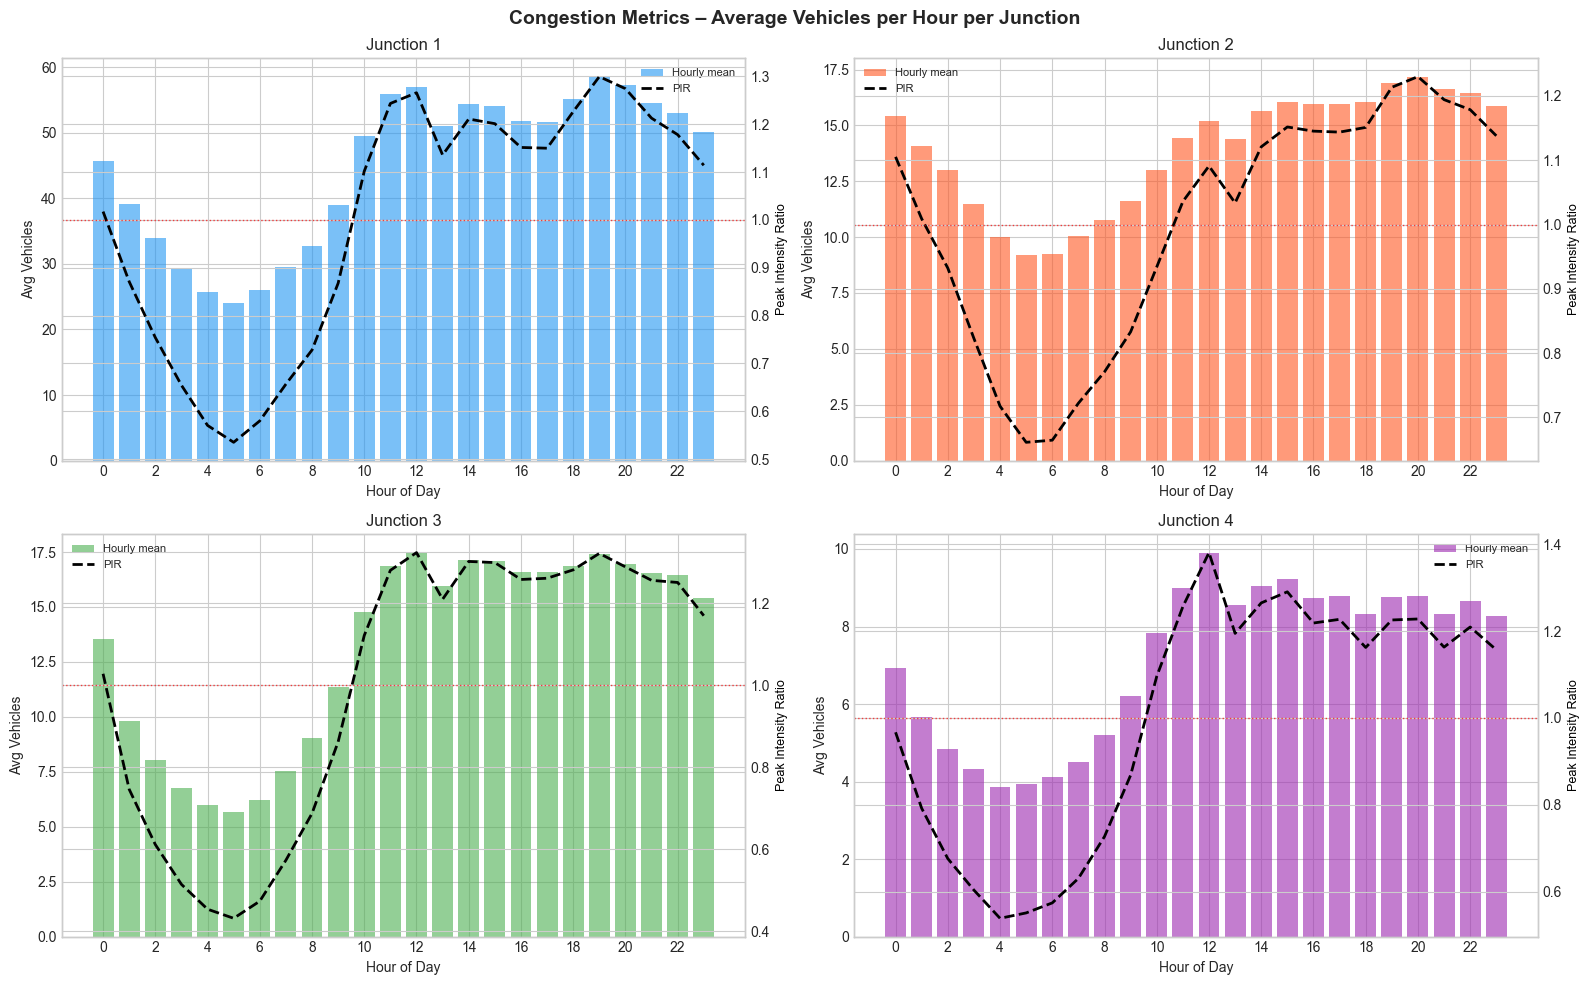

  [Saved] PH01_congestion_metrics.png


In [9]:
# ─────────────────────────────────────────────────────
# STEP 1 – LOAD CLEANED DATA
# ─────────────────────────────────────────────────────
print("=" * 60)
print("STEP 1 – LOAD CLEANED DATA")
print("=" * 60)
 
df = pd.read_csv(
    r"C:\Users\syin\Downloads\Uber_project\Datasets\cleaned_traffic_data.csv"
)
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values(["junction", "datetime"]).reset_index(drop=True)
 
# Ensure all needed columns exist
for col in ["hour", "dayofweek", "month", "year", "quarter",
            "is_weekend", "is_event", "is_holiday"]:
    if col not in df.columns:
        if col == "hour":        df["hour"]       = df["datetime"].dt.hour
        if col == "dayofweek":   df["dayofweek"]  = df["datetime"].dt.dayofweek
        if col == "month":       df["month"]      = df["datetime"].dt.month
        if col == "year":        df["year"]       = df["datetime"].dt.year
        if col == "quarter":     df["quarter"]    = df["datetime"].dt.quarter
        if col == "is_weekend":  df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
        if col in ["is_event", "is_holiday"]: df[col] = 0
 
WEATHER = [c for c in ["temp", "rhum", "wspd", "pres", "dwpt", "wdir"]
           if c in df.columns]
 
print(f"  Shape     : {df.shape}")
print(f"  Junctions : {sorted(df['junction'].unique())}")
print(f"  Date range: {df['datetime'].min().date()} → {df['datetime'].max().date()}")
print(f"  Weather   : {WEATHER}")
 
 
# ═════════════════════════════════════════════════════
# TASK 1 – CONGESTION METRICS
# ═════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("TASK 1 – CONGESTION METRICS")
print("=" * 60)
 
# ── 1a. Average vehicles per hour per junction ───────
hourly_avg = df.groupby(["junction", "hour"])["Vehicles"] \
               .agg(mean="mean", std="std", median="median",
                    q75=lambda x: x.quantile(0.75)) \
               .reset_index()
 
print("\n  Avg vehicles per hour (all junctions):")
print(hourly_avg.groupby("junction")["mean"].describe().round(2).to_string())
 
# ── 1b. Peak Intensity Ratio (PIR) ──────────────────
# PIR = hour_avg / daily_avg  — values > 1 mean above-average hours
daily_avg = df.groupby("junction")["Vehicles"].mean()
hourly_avg["daily_avg"] = hourly_avg["junction"].map(daily_avg)
hourly_avg["PIR"] = (hourly_avg["mean"] / hourly_avg["daily_avg"]).round(4)
 
print("\n  Peak Intensity Ratio per junction (top 5 hours each):")
for jn in sorted(df["junction"].unique()):
    top = hourly_avg[hourly_avg["junction"] == jn].nlargest(5, "PIR")
    print(f"\n    Junction {jn}:")
    print(top[["hour", "mean", "PIR"]].to_string(index=False))
 
# ── 1c. Congestion Index (Z-score per junction) ──────
# Z = (hour_avg − mean) / std — how many SDs above normal
for jn in sorted(df["junction"].unique()):
    mask = hourly_avg["junction"] == jn
    vals = hourly_avg.loc[mask, "mean"]
    hourly_avg.loc[mask, "z_score"] = stats.zscore(vals)
 
# ── 1d. Rolling 3-hour moving average ───────────────
# Smooths the hourly traffic curve per junction
df["rolling_3h"] = df.groupby("junction")["Vehicles"] \
                     .transform(lambda x: x.rolling(3, center=True).mean()
                                           .fillna(x))
 
print("\n  Congestion metrics computed: PIR, Z-score, rolling_3h mean")
 
 
# ── Plot 1: Hourly avg + congestion metrics ──────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Congestion Metrics – Average Vehicles per Hour per Junction",
             fontsize=14, fontweight="bold")
 
for ax, jn in zip(axes.flat, sorted(df["junction"].unique())):
    sub = hourly_avg[hourly_avg["junction"] == jn].sort_values("hour")
    ax.bar(sub["hour"], sub["mean"], color=PALETTE[jn-1],
           alpha=0.6, label="Hourly mean")
    ax2 = ax.twinx()
    ax2.plot(sub["hour"], sub["PIR"], "k--", lw=2, label="PIR")
    ax2.axhline(1.0, color="red", lw=1, ls=":", alpha=0.7)
    ax2.set_ylabel("Peak Intensity Ratio", color="black", fontsize=9)
    ax.set_title(JN_LABELS[jn])
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Avg Vehicles")
    ax.set_xticks(range(0, 24, 2))
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8)
 
savefig("PH01_congestion_metrics.png")
plt.show()
 


TASK 2 – PEAK HOUR IDENTIFICATION

  Peak hours identified per junction:

  Junction 1:
    Z-score (z>1.0) peaks : [12, 19, 20]
    IQR fence peaks       : []
    Moving avg peaks      : [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

  Junction 2:
    Z-score (z>1.0) peaks : [19, 20, 21]
    IQR fence peaks       : []
    Moving avg peaks      : [14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

  Junction 3:
    Z-score (z>1.0) peaks : []
    IQR fence peaks       : []
    Moving avg peaks      : [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

  Junction 4:
    Z-score (z>1.0) peaks : [12, 15]
    IQR fence peaks       : []
    Moving avg peaks      : [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]

  Kruskal-Wallis test (is hourly traffic significantly different?):
    Junction 1: H=3995.66, p=0.0000e+00  ***
    Junction 2: H=2458.83, p=0.0000e+00  ***
    Junction 3: H=5149.21, p=0.0000e+00  ***
    Junction 4: H=1892.82, p=0.0000e+00  ***


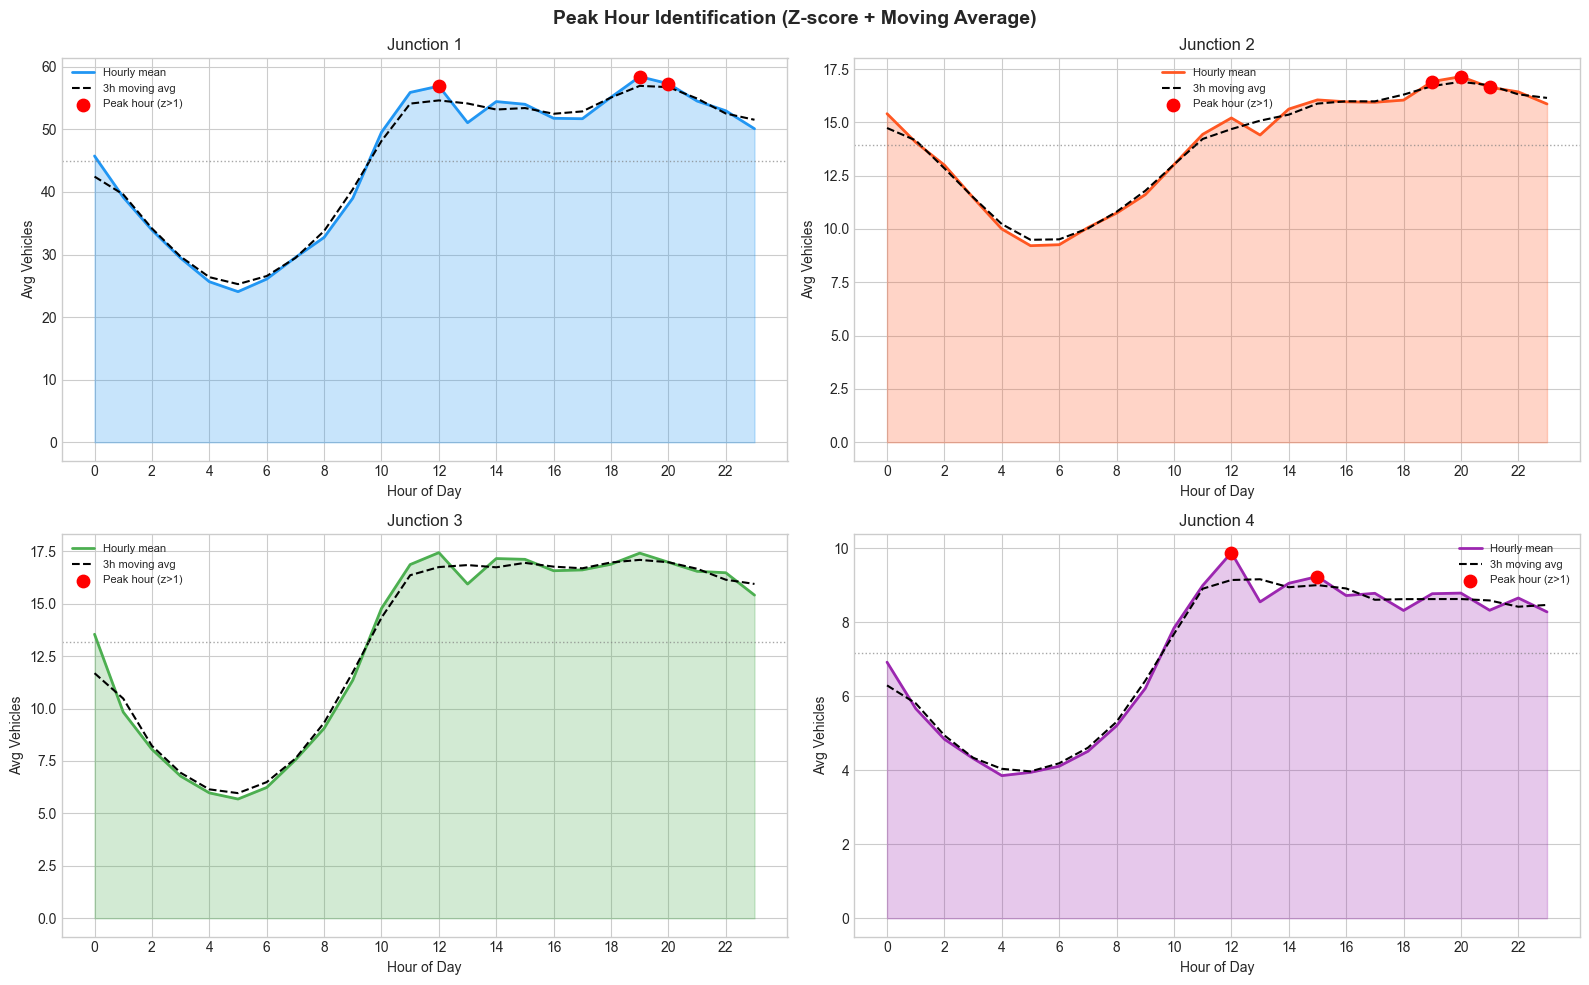

  [Saved] PH02_peak_hour_identification.png


In [10]:
# ═════════════════════════════════════════════════════
# TASK 2 – IDENTIFY PEAK HOURS
# ═════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("TASK 2 – PEAK HOUR IDENTIFICATION")
print("=" * 60)
 
# ── 2a. Z-score method: peak if z > 1.0 ─────────────
hourly_avg["is_peak_zscore"] = (hourly_avg["z_score"] > 1.0).astype(int)
 
# ── 2b. IQR upper fence method ───────────────────────
peak_hours_iqr = {}
for jn in sorted(df["junction"].unique()):
    sub  = hourly_avg[hourly_avg["junction"] == jn]
    q1   = sub["mean"].quantile(0.25)
    q3   = sub["mean"].quantile(0.75)
    fence= q3 + 0.5 * (q3 - q1)            # relaxed IQR for peak detection
    peaks= sub[sub["mean"] >= fence]["hour"].tolist()
    peak_hours_iqr[jn] = sorted(peaks)
 
hourly_avg["is_peak_iqr"] = hourly_avg.apply(
    lambda r: 1 if r["hour"] in peak_hours_iqr[r["junction"]] else 0, axis=1)
 
# ── 2c. Moving average smoothed peak ────────────────
# Apply 3-hour rolling average to hourly means, then find peaks
ma_peaks = {}
for jn in sorted(df["junction"].unique()):
    sub    = hourly_avg[hourly_avg["junction"] == jn].sort_values("hour")
    ma     = sub["mean"].rolling(3, center=True, min_periods=1).mean()
    thresh = ma.mean() + 0.5 * ma.std()
    peaks  = sub[ma >= thresh]["hour"].tolist()
    ma_peaks[jn] = sorted(peaks)
 
print("\n  Peak hours identified per junction:")
for jn in sorted(df["junction"].unique()):
    z_peaks  = hourly_avg[(hourly_avg["junction"] == jn) &
                           (hourly_avg["is_peak_zscore"] == 1)]["hour"].tolist()
    print(f"\n  Junction {jn}:")
    print(f"    Z-score (z>1.0) peaks : {sorted(z_peaks)}")
    print(f"    IQR fence peaks       : {peak_hours_iqr[jn]}")
    print(f"    Moving avg peaks      : {ma_peaks[jn]}")
 
# ── 2d. Kruskal-Wallis test: do hours differ? ────────
print("\n  Kruskal-Wallis test (is hourly traffic significantly different?):")
for jn in sorted(df["junction"].unique()):
    sub    = df[df["junction"] == jn]
    groups = [sub[sub["hour"] == h]["Vehicles"].values for h in range(24)]
    h_stat, p = kruskal(*groups)
    sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    print(f"    Junction {jn}: H={h_stat:.2f}, p={p:.4e}  {sig}")
 
# ── Plot 2: Peak hour identification ─────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Peak Hour Identification (Z-score + Moving Average)",
             fontsize=14, fontweight="bold")
 
for ax, jn in zip(axes.flat, sorted(df["junction"].unique())):
    sub  = hourly_avg[hourly_avg["junction"] == jn].sort_values("hour")
    ma   = sub["mean"].rolling(3, center=True, min_periods=1).mean()
    peak_mask = sub["is_peak_zscore"] == 1
 
    ax.fill_between(sub["hour"], sub["mean"], alpha=0.25, color=PALETTE[jn-1])
    ax.plot(sub["hour"], sub["mean"], lw=2, color=PALETTE[jn-1], label="Hourly mean")
    ax.plot(sub["hour"], ma, "k--", lw=1.5, label="3h moving avg")
    ax.scatter(sub[peak_mask]["hour"], sub[peak_mask]["mean"],
               color="red", s=80, zorder=5, label="Peak hour (z>1)")
    ax.axhline(sub["mean"].mean(), color="gray", lw=1, ls=":", alpha=0.7)
    ax.set_title(JN_LABELS[jn])
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Avg Vehicles")
    ax.set_xticks(range(0, 24, 2))
    ax.legend(fontsize=8)
 
savefig("PH02_peak_hour_identification.png")


TASK 3 – TEMPORAL PATTERNS

  3a. Weekday vs Weekend peak hour analysis:
    Junction 1: Weekday peak = 19:00 (62.4 veh)  |  Weekend peak = 19:00 (48.5 veh)
    Junction 2: Weekday peak = 20:00 (18.5 veh)  |  Weekend peak = 22:00 (14.1 veh)
    Junction 3: Weekday peak = 12:00 (18.0 veh)  |  Weekend peak = 20:00 (17.7 veh)
    Junction 4: Weekday peak = 12:00 (10.3 veh)  |  Weekend peak = 12:00 (8.9 veh)


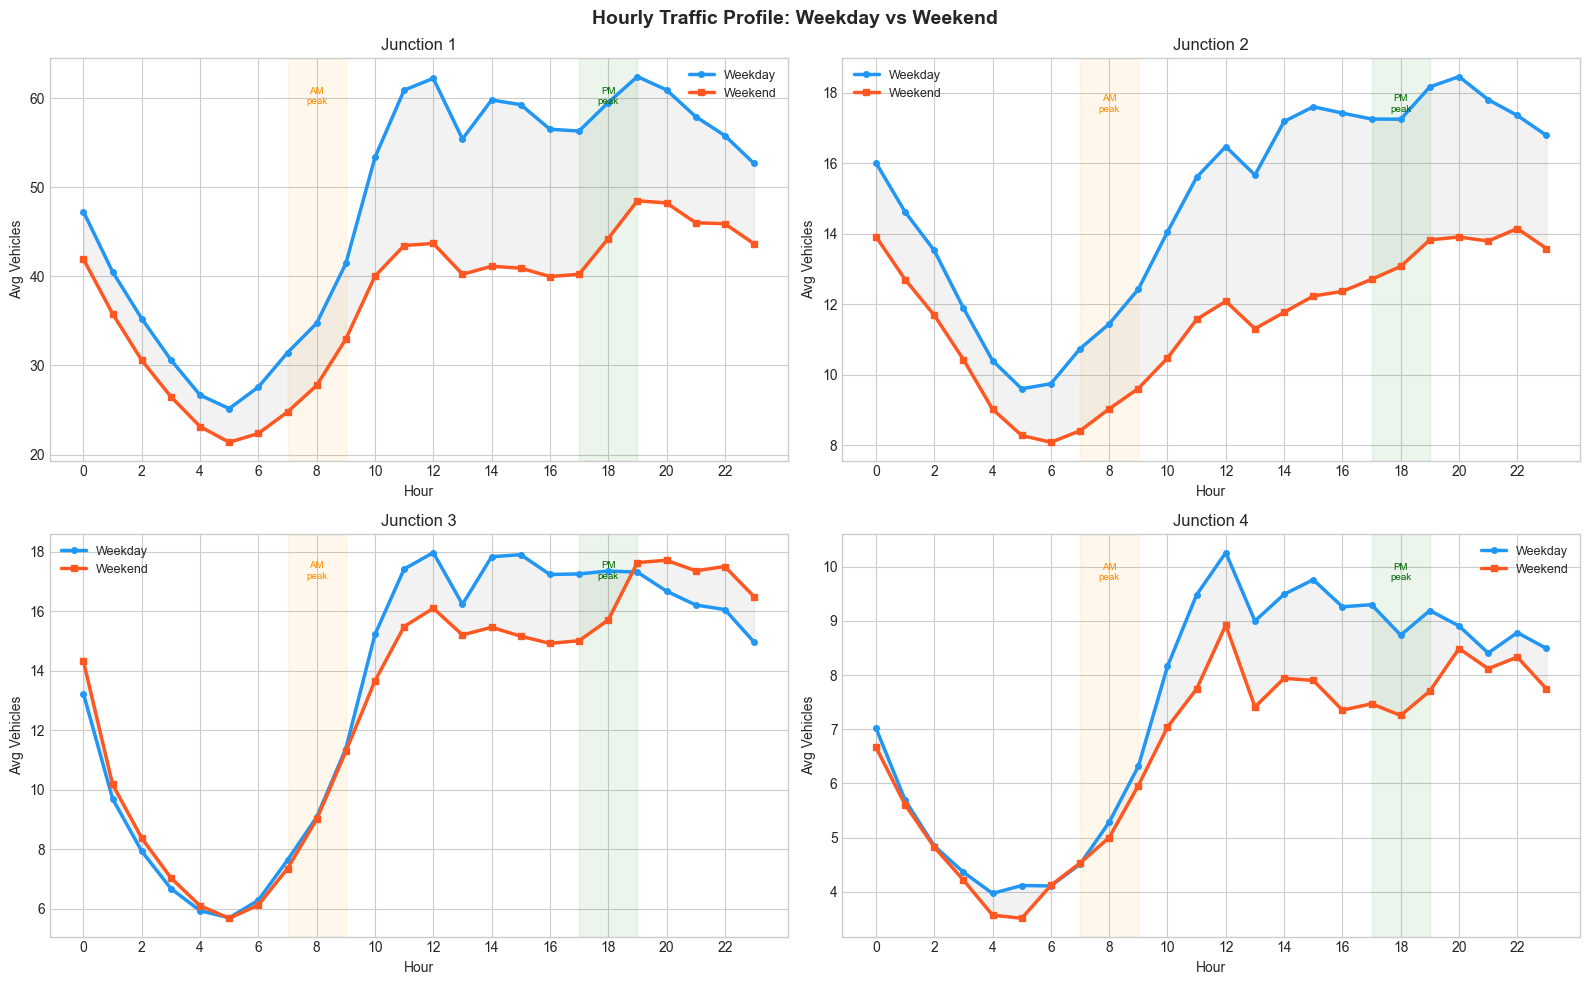

  [Saved] PH03_weekday_weekend_profile.png


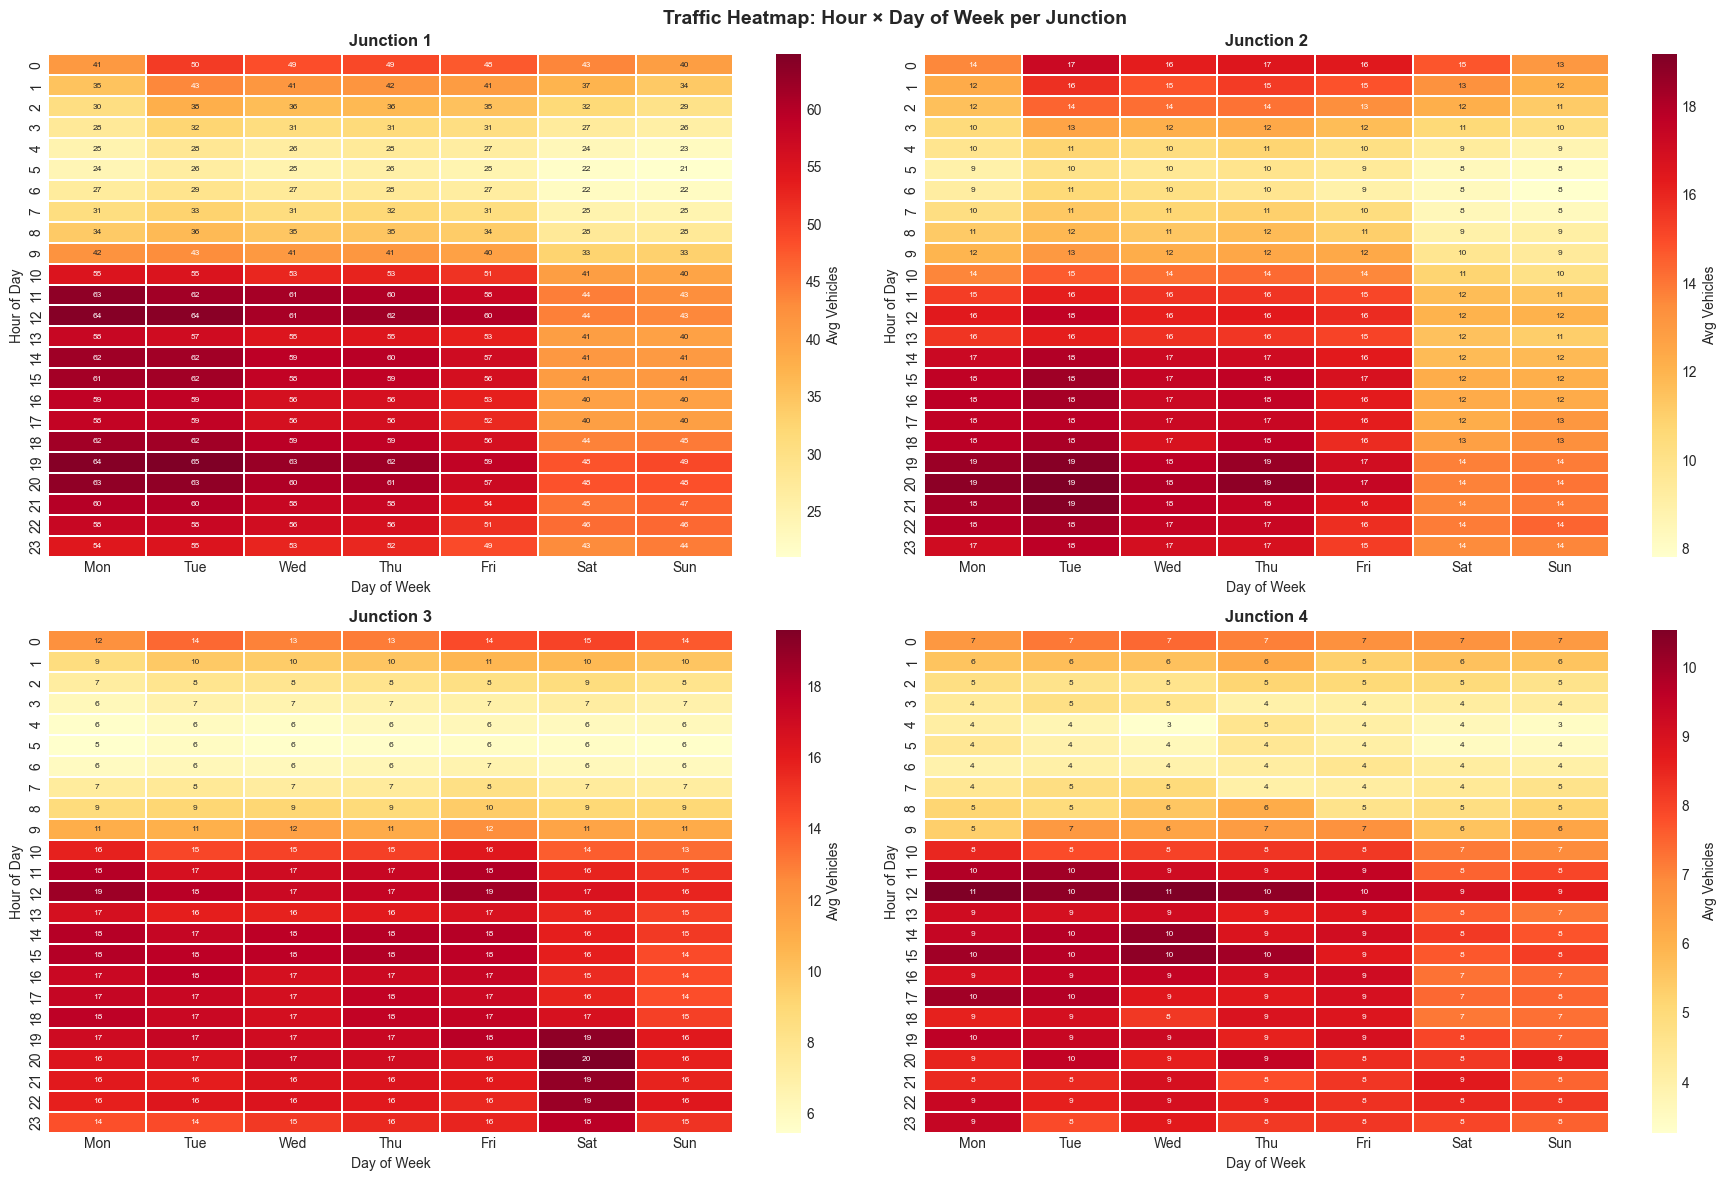

  [Saved] PH04_heatmap_hour_dow.png

  3c. Monthly peak hour shift:
 junction  month  hour  Vehicles
        1      1    20 55.017241
        1      2    19 58.622642
        1      3    19 60.482759
        1      4    12 57.142857
        1      5    19 63.551724
        1      6    19 68.517857
        1      7    19 55.897436
        1      8    19 57.256410
        1      9    19 64.789474
        1     10    19 62.102564
        1     11    19 51.107143
        1     12    12 49.931034
        2      1    20 16.017241
        2      2    20 17.811321
        2      3    20 18.982759
        2      4    19 18.375000
        2      5    20 19.413793
        2      6    19 19.875000
        2      7    20 16.076923
        2      8    20 16.128205
        2      9    20 17.078947
        2     10    19 17.692308
        2     11    20 15.232143
        2     12    19 13.741379
        3      1    21 17.258621
        3      2    15 20.622642
        3      3    12 17.629310
        

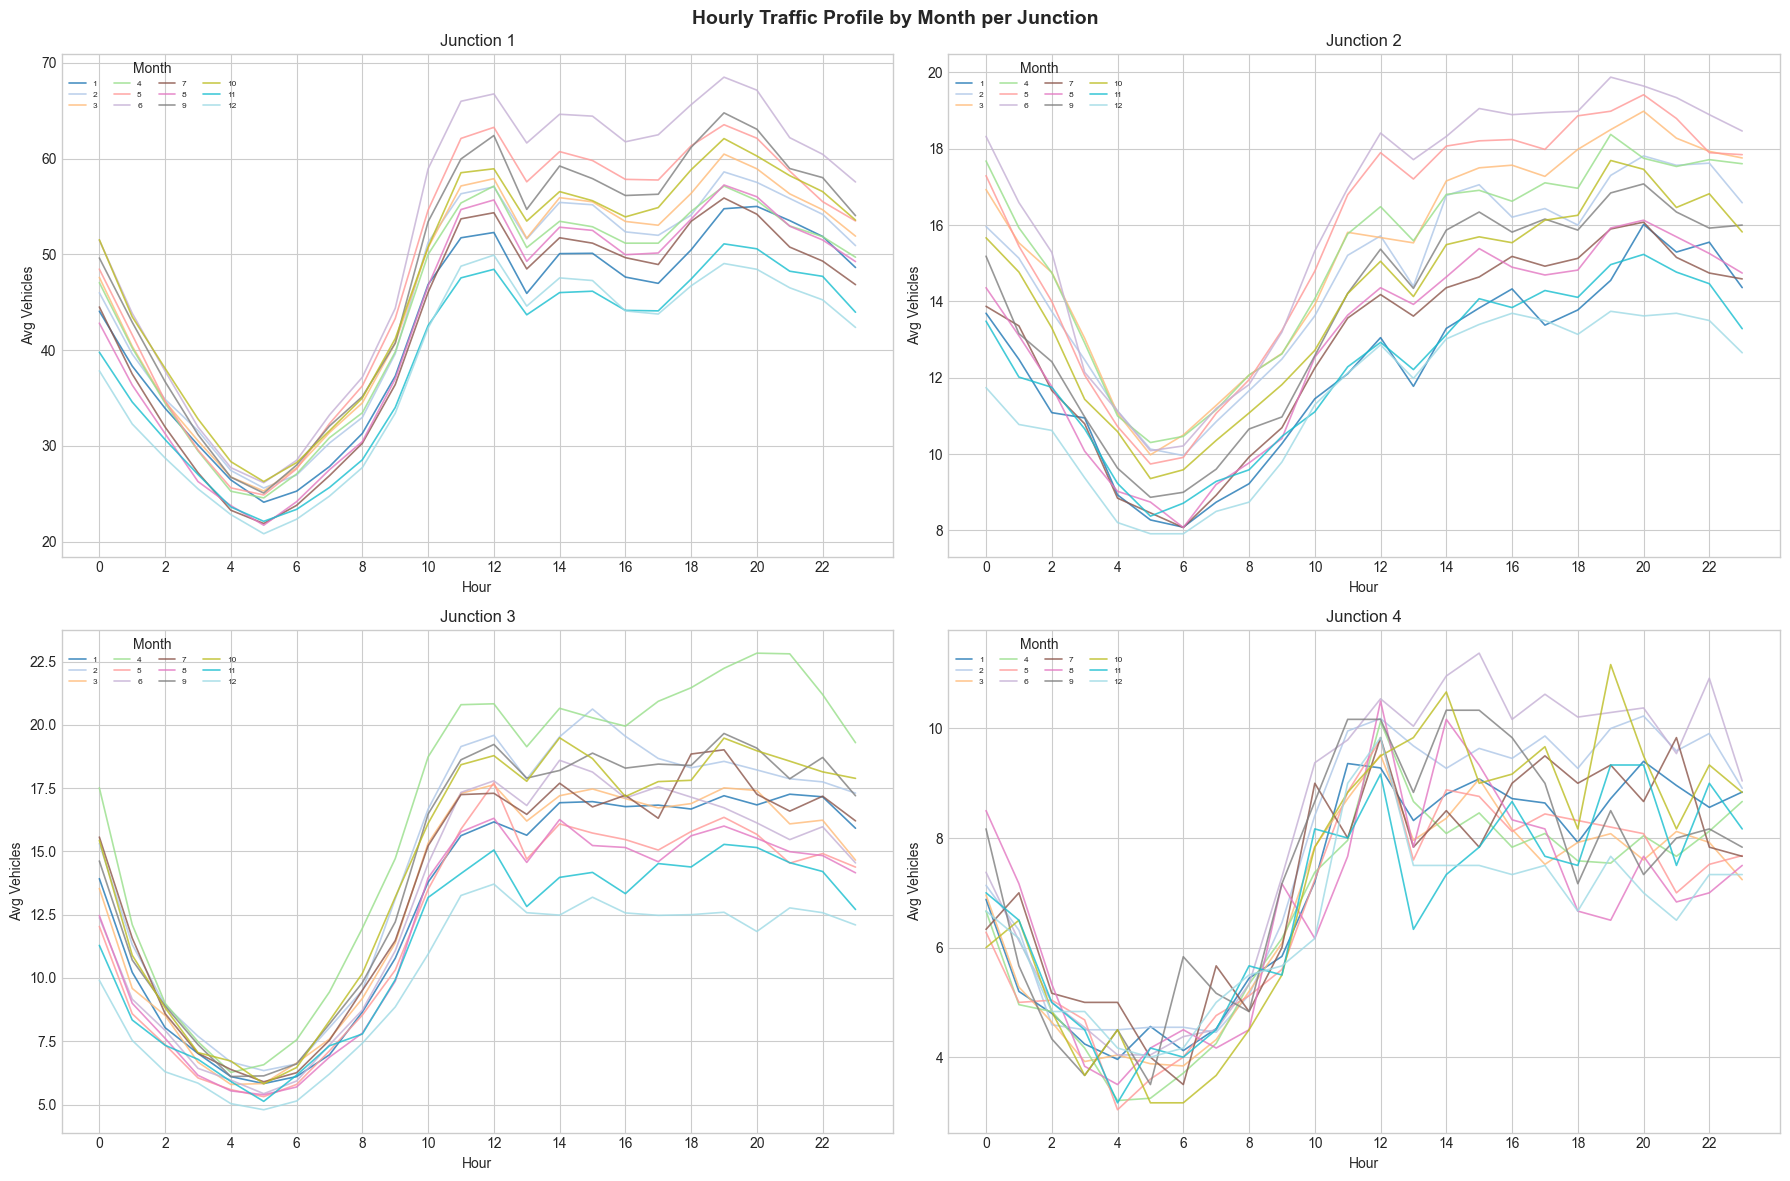

  [Saved] PH05_monthly_hourly_profiles.png

  3d. Seasonal decomposition (Junction 1, daily):


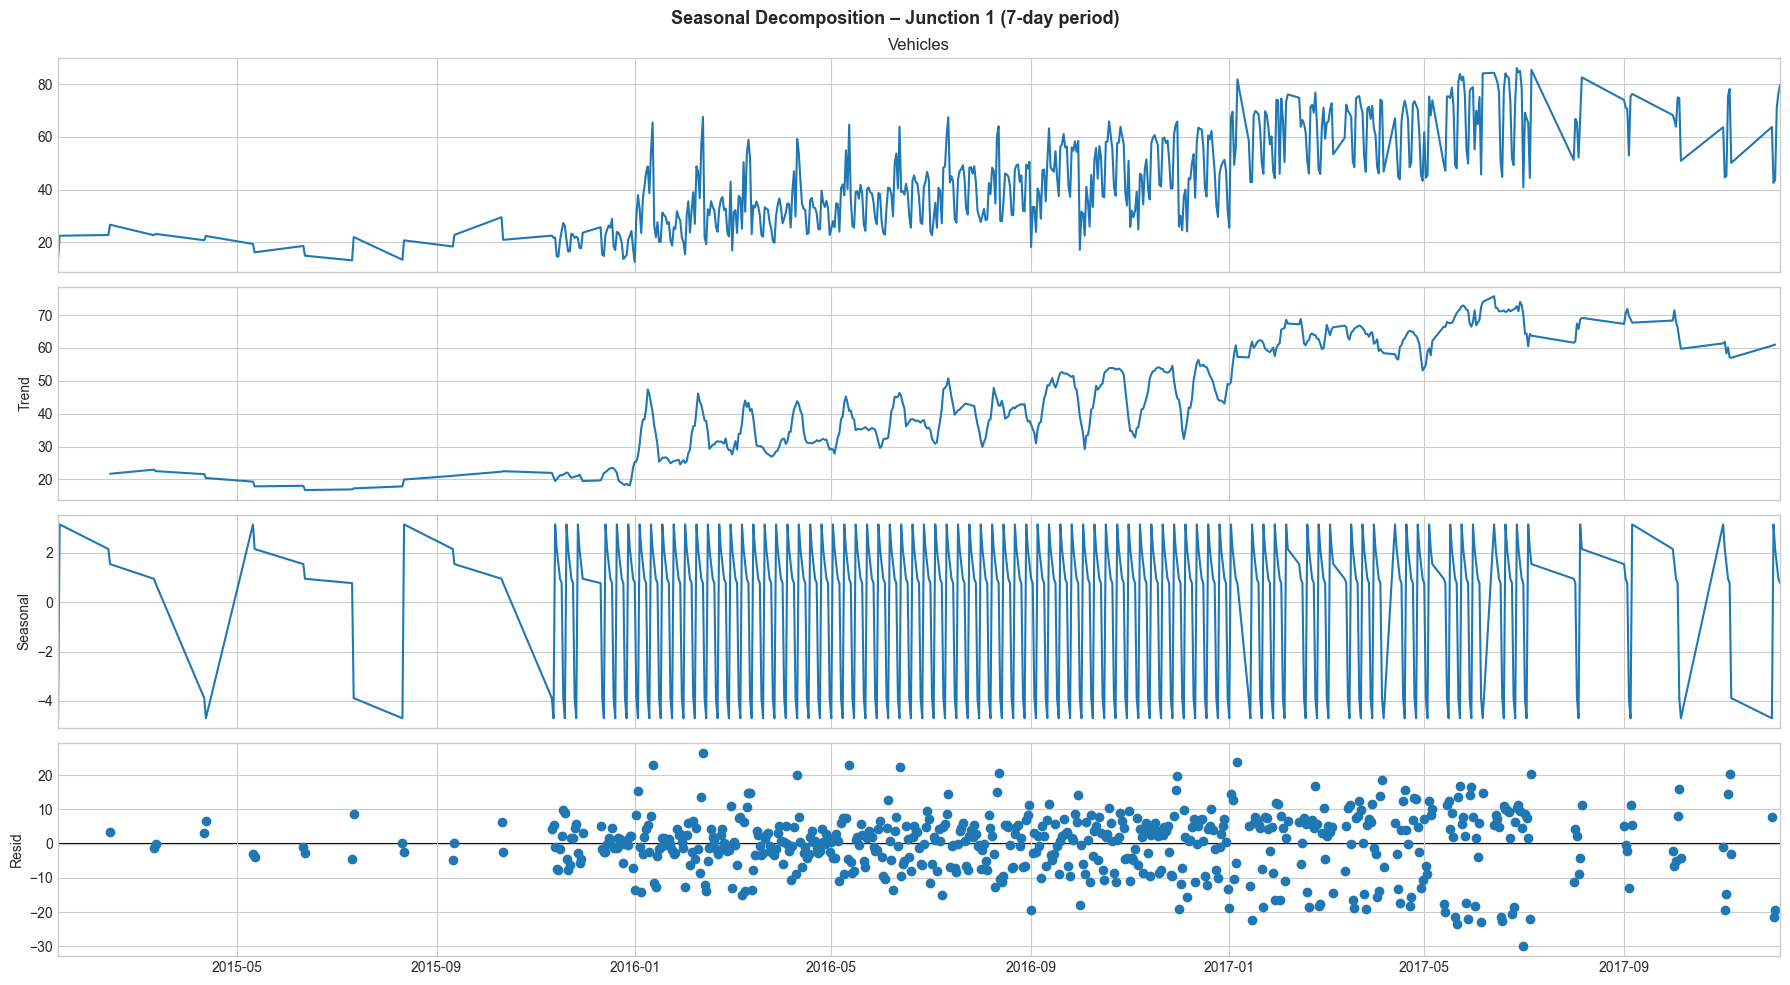

  [Saved] PH06_seasonal_decomposition.png

  3e. Year-over-year peak hour per junction:
    Junction 1 | 2015: peak at 11:00 (28.3 avg vehicles)
    Junction 1 | 2016: peak at 19:00 (51.5 avg vehicles)
    Junction 1 | 2017: peak at 19:00 (83.1 avg vehicles)
    Junction 2 | 2015: peak at 20:00 (10.0 avg vehicles)
    Junction 2 | 2016: peak at 20:00 (14.8 avg vehicles)
    Junction 2 | 2017: peak at 20:00 (24.2 avg vehicles)
    Junction 3 | 2015: peak at 12:00 (7.3 avg vehicles)
    Junction 3 | 2016: peak at 19:00 (16.9 avg vehicles)
    Junction 3 | 2017: peak at 12:00 (22.4 avg vehicles)
    Junction 4 | 2017: peak at 12:00 (9.9 avg vehicles)


In [12]:
# ═════════════════════════════════════════════════════
# TASK 3 – TEMPORAL PATTERNS
# ═════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("TASK 3 – TEMPORAL PATTERNS")
print("=" * 60)
 
# ── 3a. Weekday vs Weekend ────────────────────────────
print("\n  3a. Weekday vs Weekend peak hour analysis:")
for jn in sorted(df["junction"].unique()):
    sub = df[df["junction"] == jn]
    wd_peak = sub[sub["is_weekend"] == 0].groupby("hour")["Vehicles"].mean().idxmax()
    we_peak = sub[sub["is_weekend"] == 1].groupby("hour")["Vehicles"].mean().idxmax()
    wd_val  = sub[sub["is_weekend"] == 0].groupby("hour")["Vehicles"].mean().max()
    we_val  = sub[sub["is_weekend"] == 1].groupby("hour")["Vehicles"].mean().max()
    print(f"    Junction {jn}: Weekday peak = {wd_peak:02d}:00 "
          f"({wd_val:.1f} veh)  |  Weekend peak = {we_peak:02d}:00 ({we_val:.1f} veh)")
 
# ── Plot 3: Weekday vs Weekend hourly profile ─────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Hourly Traffic Profile: Weekday vs Weekend",
             fontsize=14, fontweight="bold")
 
for ax, jn in zip(axes.flat, sorted(df["junction"].unique())):
    sub = df[df["junction"] == jn]
    wd  = sub[sub["is_weekend"] == 0].groupby("hour")["Vehicles"].mean()
    we  = sub[sub["is_weekend"] == 1].groupby("hour")["Vehicles"].mean()
    ax.plot(wd.index, wd.values, lw=2.5, color="#2196F3",
            marker="o", ms=4, label="Weekday")
    ax.plot(we.index, we.values, lw=2.5, color="#FF5722",
            marker="s", ms=4, label="Weekend")
    ax.fill_between(wd.index, wd.values, we.values, alpha=0.1, color="gray")
    ax.axvspan(7, 9,  alpha=0.08, color="orange")
    ax.axvspan(17, 19, alpha=0.08, color="green")
    ax.set_title(JN_LABELS[jn])
    ax.set_xlabel("Hour"); ax.set_ylabel("Avg Vehicles")
    ax.set_xticks(range(0, 24, 2))
    ax.legend(fontsize=9)
    ax.text(8,  ax.get_ylim()[1]*0.92, "AM\npeak", ha="center",
            fontsize=7, color="darkorange")
    ax.text(18, ax.get_ylim()[1]*0.92, "PM\npeak", ha="center",
            fontsize=7, color="darkgreen")
 
savefig("PH03_weekday_weekend_profile.png")
 
# ── 3b. Hour × Day-of-Week heatmap ───────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("Traffic Heatmap: Hour × Day of Week per Junction",
             fontsize=14, fontweight="bold")
 
for ax, jn in zip(axes.flat, sorted(df["junction"].unique())):
    pivot = df[df["junction"] == jn].pivot_table(
        index="hour", columns="dayofweek",
        values="Vehicles", aggfunc="mean")
    pivot.columns = DAY_NAMES
    sns.heatmap(pivot, cmap="YlOrRd", ax=ax, linewidths=0.2,
                cbar_kws={"label": "Avg Vehicles"},
                annot=True, fmt=".0f", annot_kws={"size": 6})
    ax.set_title(JN_LABELS[jn], fontweight="bold")
    ax.set_xlabel("Day of Week"); ax.set_ylabel("Hour of Day")
 
savefig("PH04_heatmap_hour_dow.png")
 
# ── 3c. Monthly peak hour variation ──────────────────
print("\n  3c. Monthly peak hour shift:")
monthly_peak = df.groupby(["junction", "month", "hour"])["Vehicles"].mean() \
                 .reset_index()
monthly_peak_hour = monthly_peak.loc[
    monthly_peak.groupby(["junction", "month"])["Vehicles"].idxmax()
][["junction", "month", "hour", "Vehicles"]]
 
print(monthly_peak_hour.to_string(index=False))
 
# ── Plot 4: Monthly hourly profiles ──────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("Hourly Traffic Profile by Month per Junction",
             fontsize=14, fontweight="bold")
cmap = plt.cm.get_cmap("tab20", 12)
 
for ax, jn in zip(axes.flat, sorted(df["junction"].unique())):
    for m in sorted(df["month"].unique()):
        sub = df[(df["junction"] == jn) & (df["month"] == m)]
        hr  = sub.groupby("hour")["Vehicles"].mean()
        ax.plot(hr.index, hr.values, lw=1.2, alpha=0.8,
                color=cmap(m - 1), label=str(m))
    ax.set_title(JN_LABELS[jn])
    ax.set_xlabel("Hour"); ax.set_ylabel("Avg Vehicles")
    ax.set_xticks(range(0, 24, 2))
    ax.legend(title="Month", fontsize=6, ncol=4)
 
savefig("PH05_monthly_hourly_profiles.png")
 
# ── 3d. Seasonal decomposition ───────────────────────
print("\n  3d. Seasonal decomposition (Junction 1, daily):")
j1_daily = df[df["junction"] == 1] \
             .set_index("datetime")["Vehicles"] \
             .resample("D").mean().dropna()
 
try:
    result = seasonal_decompose(j1_daily, model="additive", period=7)
    fig = result.plot()
    fig.set_size_inches(18, 10)
    fig.suptitle("Seasonal Decomposition – Junction 1 (7-day period)",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{OUT}\\PH06_seasonal_decomposition.png", dpi=150)
    plt.show()
    plt.close()
    print("  [Saved] PH06_seasonal_decomposition.png")
except Exception as e:
    print(f"  Decomposition skipped: {e}")
 
# ── 3e. Year-over-year peak hour comparison ──────────
print("\n  3e. Year-over-year peak hour per junction:")
for jn in sorted(df["junction"].unique()):
    sub = df[df["junction"] == jn]
    for yr in sorted(sub["year"].unique()):
        peak_hr = sub[sub["year"] == yr].groupby("hour")["Vehicles"] \
                    .mean().idxmax()
        peak_v  = sub[sub["year"] == yr].groupby("hour")["Vehicles"] \
                    .mean().max()
        print(f"    Junction {jn} | {yr}: peak at {peak_hr:02d}:00 "
              f"({peak_v:.1f} avg vehicles)")
 
 


TASK 4 – INFLUENCING FACTORS

  4a. Spearman correlation (weather vs Vehicles):
  Feature            r       p-value  Significance
  --------------------------------------------------
  temp         -0.0434    1.8222e-21  ***
  rhum         +0.0500    4.5278e-28  ***
  wspd         +0.0085    6.2790e-02  ns
  pres         -0.1010   2.3147e-109  ***
  dwpt         +0.0340    8.7432e-14  ***
  wdir         +0.0388    1.7593e-17  ***

  4b. Event impact (Mann-Whitney U test):
  Event:  mean_normal=22.61  mean_event=20.64  diff=-1.97  p=1.5944e-07  ***
  Holiday:  mean_normal=22.53  mean_holiday=21.75  diff=-0.79  p=7.7523e-02  ns

  4c. OLS Regression (weather + event flags → Vehicles):

  R² = 0.0704  |  Adj R² = 0.0702
  F-stat = 303.65  |  p = 0.0000e+00

  Coefficients (significant at p < 0.05):
   Feature     Coef  p-value  Significant
     const 964.4937 0.000000         True
      temp  -0.4779 0.000000         True
      rhum  -0.0508 0.002375         True
      wspd  -0.2053 0.0

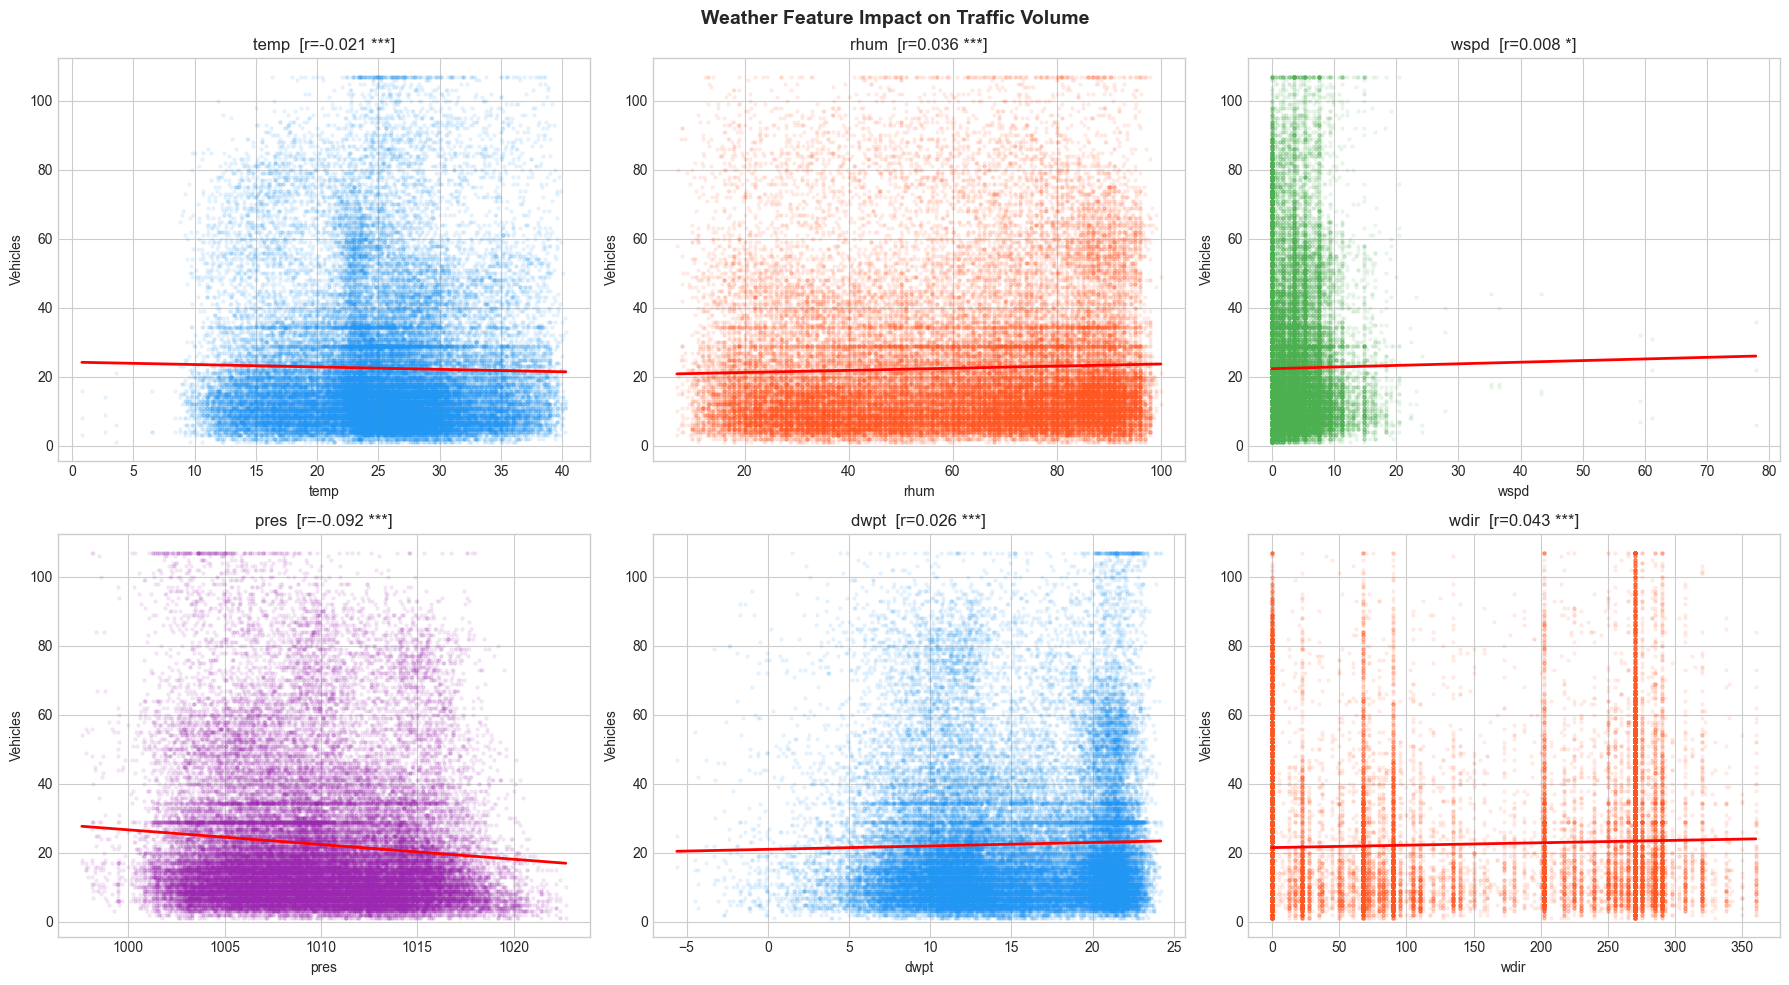

  [Saved] PH07_weather_vs_vehicles.png


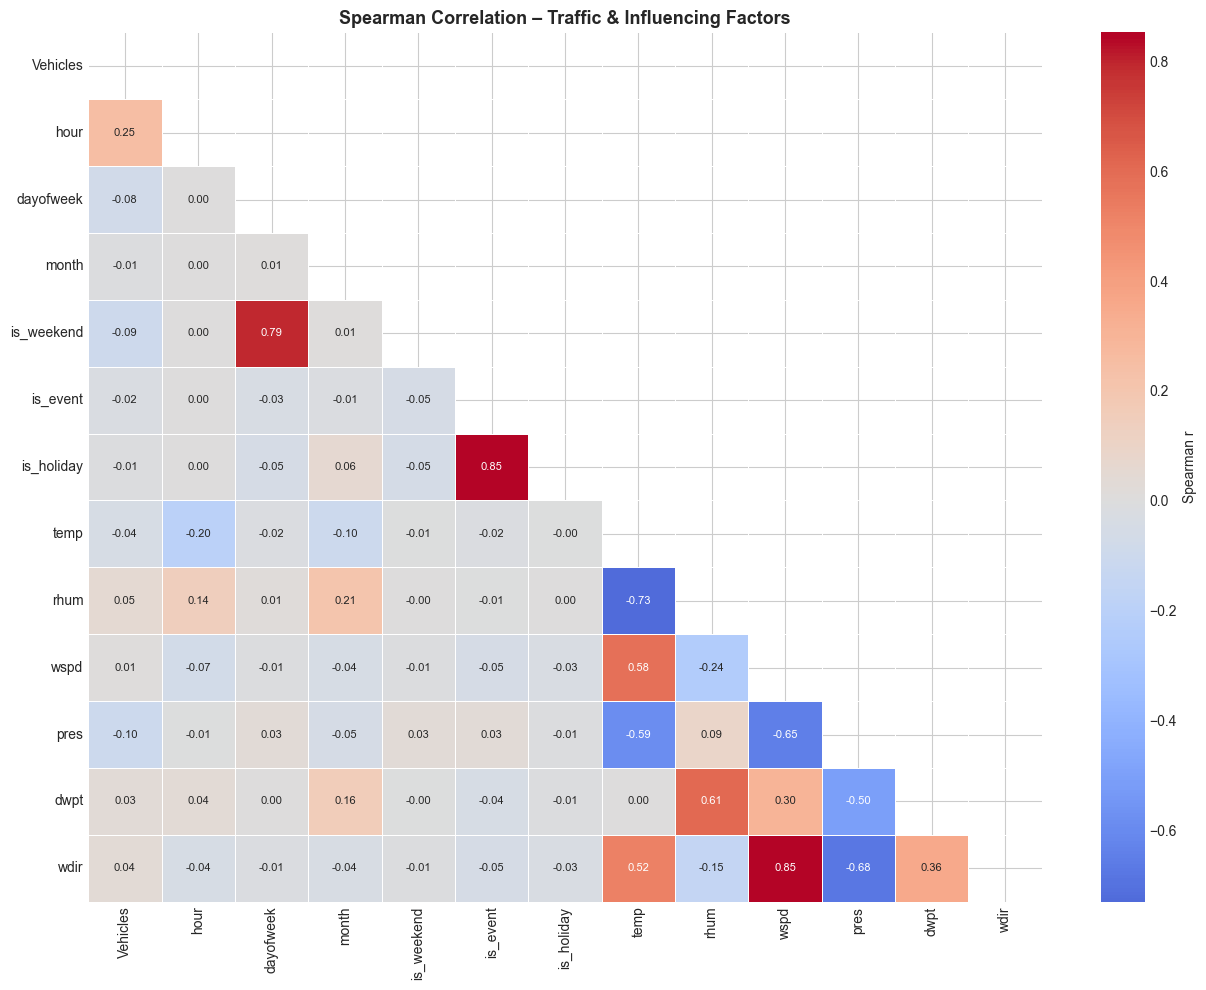

  [Saved] PH08_factor_correlation_heatmap.png


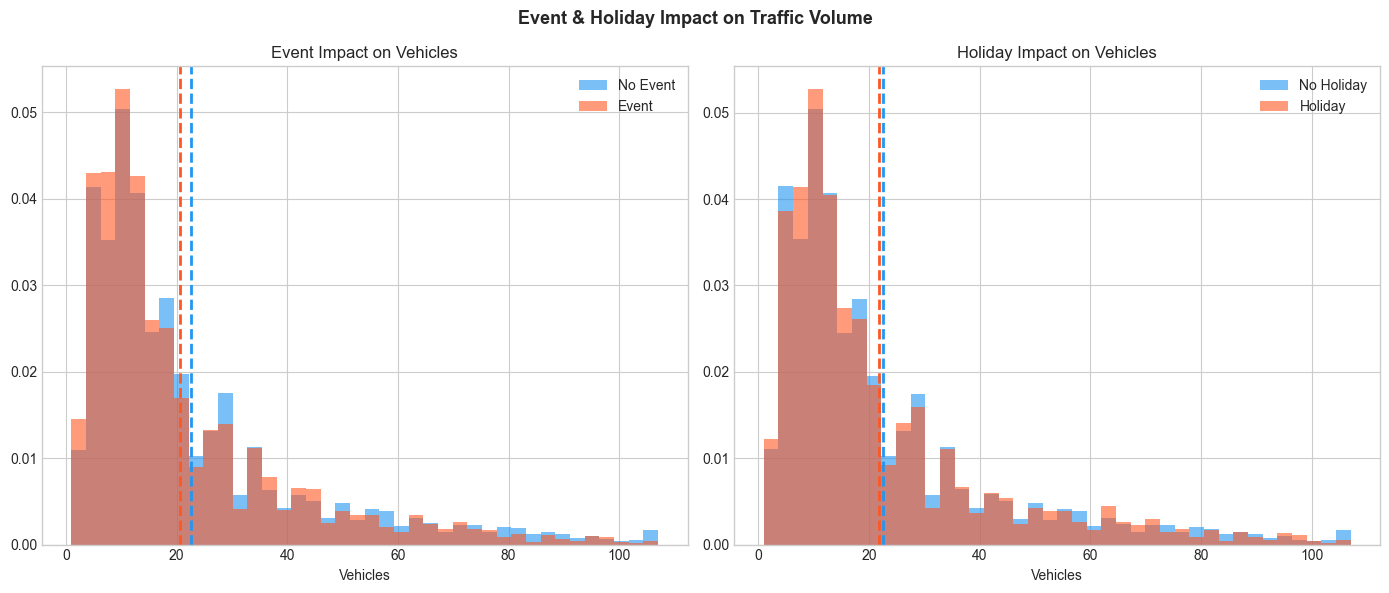

  [Saved] PH09_event_holiday_impact.png


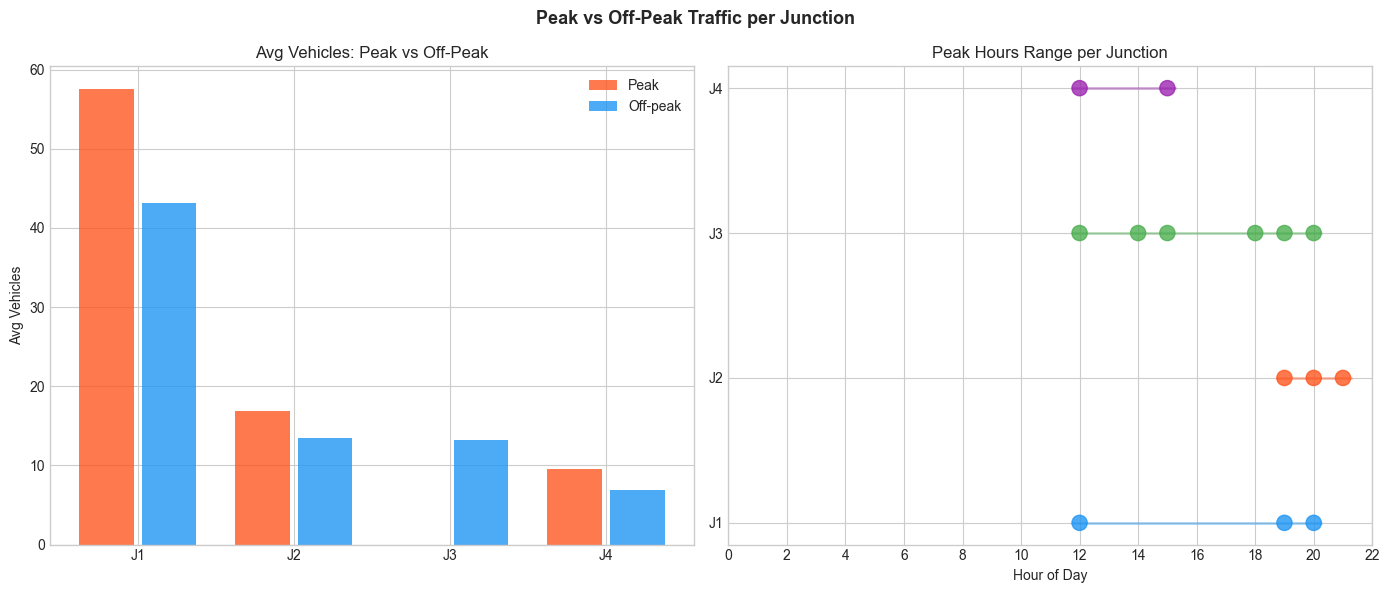

  [Saved] PH10_peak_summary.png


<Figure size 640x480 with 0 Axes>

  [Saved] PH11_peak_summary.png


In [18]:
# ═════════════════════════════════════════════════════
# TASK 4 – INFLUENCING FACTORS
# ═════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("TASK 4 – INFLUENCING FACTORS")
print("=" * 60)
 
# ── 4a. Spearman correlation: weather vs Vehicles ────
print("\n  4a. Spearman correlation (weather vs Vehicles):")
print(f"  {'Feature':<10}  {'r':>8}  {'p-value':>12}  Significance")
print("  " + "-" * 50)
for col in WEATHER:
    sub = df[["Vehicles", col]].dropna()
    r, p = spearmanr(sub["Vehicles"], sub[col])
    sig  = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    print(f"  {col:<10}  {r:>+8.4f}  {p:>12.4e}  {sig}")
 
# ── 4b. Event impact: Mann-Whitney U test ────────────
print("\n  4b. Event impact (Mann-Whitney U test):")
for flag, label in [("is_event", "Event"), ("is_holiday", "Holiday")]:
    if df[flag].sum() == 0:
        print(f"  {label}: no data (all zeros) — skipping")
        continue
    grp0 = df[df[flag] == 0]["Vehicles"].dropna()
    grp1 = df[df[flag] == 1]["Vehicles"].dropna()
    u, p  = mannwhitneyu(grp0, grp1, alternative="two-sided")
    diff  = grp1.mean() - grp0.mean()
    sig   = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
    print(f"  {label}:  mean_normal={grp0.mean():.2f}  "
          f"mean_{label.lower()}={grp1.mean():.2f}  "
          f"diff={diff:+.2f}  p={p:.4e}  {sig}")
 
# ── 4c. OLS Regression: weather + event → Vehicles ──
print("\n  4c. OLS Regression (weather + event flags → Vehicles):")
reg_cols  = WEATHER + ["is_event", "is_holiday", "is_weekend",
                        "hour", "dayofweek", "month"]
reg_cols  = [c for c in reg_cols if c in df.columns]
reg_data  = df[reg_cols + ["Vehicles"]].dropna()
 
X_reg = sm.add_constant(reg_data[reg_cols])
y_reg = reg_data["Vehicles"]
model = sm.OLS(y_reg, X_reg).fit()
 
print(f"\n  R² = {model.rsquared:.4f}  |  Adj R² = {model.rsquared_adj:.4f}")
print(f"  F-stat = {model.fvalue:.2f}  |  p = {model.f_pvalue:.4e}")
print("\n  Coefficients (significant at p < 0.05):")
coef_df = pd.DataFrame({
    "Feature"  : model.params.index,
    "Coef"     : model.params.values.round(4),
    "p-value"  : model.pvalues.values.round(6),
    "Significant": model.pvalues.values < 0.05
})
print(coef_df[coef_df["Significant"]].to_string(index=False))
 
# ── 4d. Weather impact on peak vs non-peak hours ─────
#  Robust peak detection (fixes empty peak issue)

peak_lookup = {}

for jn in sorted(df["junction"].unique()):
    sub = hourly_avg[hourly_avg["junction"] == jn].copy()

    # Safety: very small data
    if len(sub) < 3:
        peak_lookup[jn] = []
        print(f"  ⚠ Junction {jn}: insufficient data")
        continue

    # ── Method 1: Z-score (primary) ──
    z_peaks = sub[sub["z_score"] > 1.0]["hour"].tolist()

    # ── Method 2: fallback → percentile ──
    if len(z_peaks) < 2:
        threshold = sub["mean"].quantile(0.75)   # top 25%
        fallback = sub[sub["mean"] >= threshold]["hour"].tolist()

        peak_lookup[jn] = sorted(fallback)

        print(f"  ⚠ Junction {jn}: using percentile fallback → {peak_lookup[jn]}")
    else:
        peak_lookup[jn] = sorted(z_peaks)
 
# ── Plot 5: Weather vs Vehicles scatter ─────────────
if WEATHER:
    n_cols = min(len(WEATHER), 6)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle("Weather Feature Impact on Traffic Volume",
                 fontsize=14, fontweight="bold")
    for i, (ax, col) in enumerate(zip(axes.flat, WEATHER[:6])):
        sub = df[["Vehicles", col]].dropna()
        ax.scatter(sub[col], sub["Vehicles"],
                   alpha=0.08, s=5, color=PALETTE[i % 4])
        m, b, r, p, _ = stats.linregress(sub[col], sub["Vehicles"])
        x_line = np.linspace(sub[col].min(), sub[col].max(), 200)
        ax.plot(x_line, m * x_line + b, "r-", lw=2)
        sig = "***" if p < 0.001 else "**" if p < 0.01 else "*"
        ax.set_title(f"{col}  [r={r:.3f} {sig}]")
        ax.set_xlabel(col); ax.set_ylabel("Vehicles")
    savefig("PH07_weather_vs_vehicles.png")
 
# ── Plot 6: Correlation heatmap (all factors) ────────
factor_cols = ["Vehicles", "hour", "dayofweek", "month",
               "is_weekend", "is_event", "is_holiday"] + WEATHER
factor_cols = [c for c in factor_cols if c in df.columns]
corr_mat    = df[factor_cols].corr(method="spearman")
 
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.4,
            annot_kws={"size": 8}, ax=ax,
            cbar_kws={"label": "Spearman r"})
ax.set_title("Spearman Correlation – Traffic & Influencing Factors",
             fontsize=13, fontweight="bold")
savefig("PH08_factor_correlation_heatmap.png")
 
# ── Plot 7: Event & Holiday impact ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Event & Holiday Impact on Traffic Volume",
             fontsize=13, fontweight="bold")
 
for ax, (col, label) in zip(axes, [("is_event", "Event"),
                                    ("is_holiday", "Holiday")]):
    if df[col].sum() == 0:
        ax.text(0.5, 0.5, f"No {label} data", ha="center",
                transform=ax.transAxes)
        continue
    grp0 = df[df[col] == 0]["Vehicles"]
    grp1 = df[df[col] == 1]["Vehicles"]
    ax.hist(grp0, bins=40, alpha=0.6, color="#2196F3",
            label=f"No {label}", density=True)
    ax.hist(grp1, bins=40, alpha=0.6, color="#FF5722",
            label=label, density=True)
    ax.axvline(grp0.mean(), color="#2196F3", lw=2, ls="--")
    ax.axvline(grp1.mean(), color="#FF5722",  lw=2, ls="--")
    ax.set_title(f"{label} Impact on Vehicles")
    ax.set_xlabel("Vehicles"); ax.legend()
 
savefig("PH09_event_holiday_impact.png")
 
# ── Plot 8: Peak hour by junction (summary bar) ──────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Peak vs Off-Peak Traffic per Junction",
             fontsize=13, fontweight="bold")

# ── Define peak_hours_all FIRST before any loop uses it ──
peak_hours_all = pd.DataFrame(
    [(jn, h) for jn, hrs in peak_lookup.items() for h in hrs],
    columns=["junction", "peak_hour"]
)

# ── Left plot: Peak vs Off-peak bar ──
for jn in sorted(df["junction"].unique()):
    sub  = df[df["junction"] == jn]
    peak = sub[sub["is_peak_hour"] == 1]["Vehicles"].mean()
    offp = sub[sub["is_peak_hour"] == 0]["Vehicles"].mean()
    axes[0].bar(jn - 0.2, peak, 0.35, color="#FF5722", alpha=0.8,
                label="Peak" if jn == 1 else "")
    axes[0].bar(jn + 0.2, offp, 0.35, color="#2196F3", alpha=0.8,
                label="Off-peak" if jn == 1 else "")

axes[0].set_xticks(sorted(df["junction"].unique()))
axes[0].set_xticklabels([f"J{j}" for j in sorted(df["junction"].unique())])
axes[0].set_title("Avg Vehicles: Peak vs Off-Peak")
axes[0].set_ylabel("Avg Vehicles")
axes[0].legend()

# ── Right plot: Peak hours scatter + hlines ──
axes[1].scatter(peak_hours_all["peak_hour"],
                peak_hours_all["junction"],
                s=120, color=[PALETTE[j-1] for j in peak_hours_all["junction"]],
                alpha=0.8, zorder=5)

for jn in sorted(df["junction"].unique()):
    phrs = peak_lookup.get(jn, [])

    if phrs:   # ✅ prevents crash
        axes[1].hlines(jn, min(phrs) - 0.3, max(phrs) + 0.3,
                       color=PALETTE[jn-1], lw=2, alpha=0.4)
    else:
        print(f"  ⚠ Junction {jn}: no peak hours even after fallback")

axes[1].set_yticks(sorted(df["junction"].unique()))
axes[1].set_yticklabels([f"J{j}" for j in sorted(df["junction"].unique())])
axes[1].set_xlabel("Hour of Day")
axes[1].set_title("Peak Hours Range per Junction")
axes[1].set_xticks(range(0, 24, 2))

savefig("PH10_peak_summary.png")

# Peak hour distribution across junctions
peak_hours_all = pd.DataFrame(
    [(jn, h) for jn, hrs in peak_lookup.items() for h in hrs],
    columns=["junction", "peak_hour"])
axes[1].scatter(peak_hours_all["peak_hour"],
                peak_hours_all["junction"],
                s=120, color=[PALETTE[j-1] for j in peak_hours_all["junction"]],
                alpha=0.8, zorder=5)
for jn in sorted(df["junction"].unique()):
    phrs = peak_hours_all[peak_hours_all["junction"] == jn]["peak_hour"].tolist()
    axes[1].hlines(jn, min(phrs) - 0.3, max(phrs) + 0.3,
                   color=PALETTE[jn-1], lw=2, alpha=0.4)
axes[1].set_yticks(sorted(df["junction"].unique()))
axes[1].set_yticklabels([f"J{j}" for j in sorted(df["junction"].unique())])
axes[1].set_xlabel("Hour of Day")
axes[1].set_title("Peak Hours Range per Junction")
axes[1].set_xticks(range(0, 24, 2))
 
savefig("PH11_peak_summary.png")

In [19]:
# ─────────────────────────────────────────────────────
# STEP 5 – SAVE RESULTS TABLE
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 5 – SAVE RESULTS")
print("=" * 60)
 
# Congestion metrics table
hourly_avg.to_csv(f"{OUT}\\congestion_metrics.csv", index=False)
print("  [Saved] congestion_metrics.csv")
 
# OLS regression summary
with open(f"{OUT}\\ols_regression_summary.txt", "w") as f:
    f.write(model.summary().as_text())
print("  [Saved] ols_regression_summary.txt")


STEP 5 – SAVE RESULTS
  [Saved] congestion_metrics.csv
  [Saved] ols_regression_summary.txt


In [20]:
# ─────────────────────────────────────────────────────
# FINAL SUMMARY
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("PEAK HOUR ANALYSIS COMPLETE")
print("=" * 60)
 
print("\n  Peak hours per junction (Z-score method):")
for jn in sorted(df["junction"].unique()):
    print(f"    Junction {jn}: {sorted(peak_lookup[jn])}")
 
print(f"""
  Plots saved
  ─────────────────────────────────────────────────────
  PH01_congestion_metrics.png      – hourly avg + PIR
  PH02_peak_hour_identification.png– Z-score + moving avg peaks
  PH03_weekday_weekend_profile.png – weekday vs weekend profiles
  PH04_heatmap_hour_dow.png        – hour x day-of-week heatmap
  PH05_monthly_hourly_profiles.png – monthly variation
  PH06_seasonal_decomposition.png  – trend/seasonal/residual
  PH07_weather_vs_vehicles.png     – weather scatter + regression
  PH08_factor_correlation_heatmap  – Spearman all factors
  PH09_event_holiday_impact.png    – event/holiday distributions
  PH10_peak_summary.png            – peak hours summary
 
  Tables saved
  ─────────────────────────────────────────────────────
  congestion_metrics.csv           – hourly PIR, z-score, etc.
  ols_regression_summary.txt       – full OLS output
""")


PEAK HOUR ANALYSIS COMPLETE

  Peak hours per junction (Z-score method):
    Junction 1: [12, 19, 20]
    Junction 2: [19, 20, 21]
    Junction 3: [12, 14, 15, 18, 19, 20]
    Junction 4: [12, 15]

  Plots saved
  ─────────────────────────────────────────────────────
  PH01_congestion_metrics.png      – hourly avg + PIR
  PH02_peak_hour_identification.png– Z-score + moving avg peaks
  PH03_weekday_weekend_profile.png – weekday vs weekend profiles
  PH04_heatmap_hour_dow.png        – hour x day-of-week heatmap
  PH05_monthly_hourly_profiles.png – monthly variation
  PH06_seasonal_decomposition.png  – trend/seasonal/residual
  PH07_weather_vs_vehicles.png     – weather scatter + regression
  PH08_factor_correlation_heatmap  – Spearman all factors
  PH09_event_holiday_impact.png    – event/holiday distributions
  PH10_peak_summary.png            – peak hours summary
 
  Tables saved
  ─────────────────────────────────────────────────────
  congestion_metrics.csv           – hourly PIR, z

In [ ]:
# ── Plot 8: Peak hour by junction (summary bar) ──────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Peak vs Off-Peak Traffic per Junction",
             fontsize=13, fontweight="bold")
 
for jn in sorted(df["junction"].unique()):
    sub  = df[df["junction"] == jn]
    peak = sub[sub["is_peak_hour"] == 1]["Vehicles"].mean()
    offp = sub[sub["is_peak_hour"] == 0]["Vehicles"].mean()
    axes[0].bar(jn - 0.2, peak, 0.35, color="#FF5722", alpha=0.8,
                label="Peak" if jn == 1 else "")
    axes[0].bar(jn + 0.2, offp, 0.35, color="#2196F3", alpha=0.8,
                label="Off-peak" if jn == 1 else "")
 
axes[0].set_xticks(sorted(df["junction"].unique()))
axes[0].set_xticklabels([f"J{j}" for j in sorted(df["junction"].unique())])
axes[0].set_title("Avg Vehicles: Peak vs Off-Peak")
axes[0].set_ylabel("Avg Vehicles")
axes[0].legend()

# Replace your current loop with this:
for jn in sorted(df["junction"].unique()):
    # Get the list of peak hours for this specific junction
    phrs = peak_hours_all[peak_hours_all["junction"] == jn]["peak_hour"].tolist()
    
    # Check if the list actually contains data
    if phrs: 
        axes[1].hlines(jn, min(phrs) - 0.3, max(phrs) + 0.3,
                       color=PALETTE[jn-1], lw=2, alpha=0.4)
    else:
        print(f"Warning: No peak hours found for Junction {jn}")

# Continue with your formatting
axes[1].set_yticks(sorted(df["junction"].unique()))
axes[1].set_yticklabels([f"J{j}" for j in sorted(df["junction"].unique())])
